# Global Coffee Production Correlation Analysis

## 1. Project Introduction and Objective

This notebook analyzes historical global coffee production across **30 crop years
(1990/91 through 2019/20)** for 55 producing countries. Each country in the dataset
is classified by the coffee variety it predominantly produces:

| Classification | Meaning |
|---|---|
| **Arabica** | Produces Arabica only (or almost only) |
| **Robusta** | Produces Robusta only (or almost only) |
| **Arabica/Robusta** | Produces both, mainly Arabica |
| **Robusta/Arabica** | Produces both, mainly Robusta |

**Objective:** determine how the production trends of these four coffee
classifications move together over time. The workflow is:

1. **Aggregate** — sum annual production across countries for each coffee type (Pandas `groupby`).
2. **Transpose** — reshape the matrix so years are rows and coffee types are columns (`.T`).
3. **Correlate** — compute the Pearson correlation matrix (`.corr(method="pearson")`).
4. **Visualize & interpret** — heatmap, trend chart, and a statistical reflection.

> **Important caveat about the data:** the classification is assigned per *country*, not
> per bean. A country's entire production is counted under its single label. For example,
> Viet Nam is labelled *Robusta/Arabica* and Brazil *Arabica/Robusta*, so the pure
> *Robusta* group does **not** include the world's largest Robusta producer. All results
> below describe these country groups, not botanical species totals.

## 2. Import Libraries

In [1]:
import re
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# Relative paths only: the notebook is run from the project root.
DATA_PATH = Path("Coffee_production.csv")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

print(f"pandas     {pd.__version__}")
print(f"numpy      {np.__version__}")
print(f"seaborn    {sns.__version__}")

pandas     3.1.1
numpy      2.5.5
seaborn    0.13.2


## 3. Load and Inspect the Dataset

The CSV is expected in the project root next to this notebook. If it is missing,
the cell below stops with an explicit message instead of producing any results.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH.resolve()}'.\n"
        "Place Coffee_production.csv in the project root (the same folder as this "
        "notebook) and re-run the notebook from the top."
    )

raw_df = pd.read_csv(DATA_PATH)
print(f"Shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
raw_df.head()

Shape: 55 rows x 33 columns


,Country,Coffee type,1990/91,1991/92,1992/93,1993/94,1994/95,1995/96,1996/97,1997/98,1998/99,1999/00,2000/01,2001/02,2002/03,2003/04,2004/05,2005/06,2006/07,2007/08,2008/09,2009/10,2010/11,2011/12,2012/13,2013/14,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,Total_production
0,Angola,Robusta/Arabica,3.000000e+06,4.740000e+06,4.680000e+06,1.980000e+06,4.620000e+06,3.720000e+06,4.260000e+06,3.840000e+06,5.100000e+06,3.300000e+06,3.000000e+06,1.260000e+06,3.420000e+06,2.280000e+06,9.000000e+05,1.500000e+06,2.100000e+06,2.160000e+06,2.280000e+06,7.800000e+05,2.100000e+06,1.740000e+06,1.980000e+06,2.100000e+06,2.340000e+06,2.460000e+06,2.700000e+06,2.100000e+06,2.520000e+06,3.120000e+06,8.208000e+07
1,Bolivia (Plurinational State of),Arabica,7.380000e+06,6.240000e+06,7.200000e+06,3.060000e+06,7.020000e+06,8.520000e+06,7.500000e+06,8.460000e+06,8.280000e+06,9.480000e+06,8.880000e+06,5.640000e+06,7.620000e+06,6.180000e+06,9.300000e+06,6.600000e+06,8.760000e+06,6.960000e+06,7.200000e+06,7.680000e+06,7.020000e+06,7.920000e+06,6.300000e+06,7.200000e+06,6.000000e+06,5.040000e+06,4.680000e+06,5.040000e+06,4.980000e+06,4.860000e+06,2.070000e+08
2,Brazil,Arabica/Robusta,1.637160e+09,1.637580e+09,2.076180e+09,1.690020e+09,1.691520e+09,1.083600e+09,1.751820e+09,1.568880e+09,2.205660e+09,2.854680e+09,1.878600e+09,1.881900e+09,2.901120e+09,1.732380e+09,2.356860e+09,1.975980e+09,2.905920e+09,2.334660e+09,3.089460e+09,2.638620e+09,3.325680e+09,2.915520e+09,3.325080e+09,3.281340e+09,3.198300e+09,3.172260e+09,3.407280e+09,3.164400e+09,3.907860e+09,3.492660e+09,7.508298e+10
3,Burundi,Arabica/Robusta,2.922000e+07,4.002000e+07,3.720000e+07,2.358000e+07,3.984000e+07,2.604000e+07,2.406000e+07,1.500000e+07,2.952000e+07,2.106000e+07,2.922000e+07,8.640000e+06,2.724000e+07,2.028000e+07,2.622000e+07,6.180000e+06,2.988000e+07,7.980000e+06,2.472000e+07,6.720000e+06,2.118000e+07,1.224000e+07,2.436000e+07,9.780000e+06,1.488000e+07,1.614000e+07,1.176000e+07,1.212000e+07,1.224000e+07,1.632000e+07,6.236400e+08
4,Ecuador,Arabica/Robusta,9.024000e+07,1.274400e+08,7.110000e+07,1.241400e+08,1.425600e+08,1.132800e+08,1.195800e+08,7.146000e+07,7.236000e+07,7.188000e+07,5.124000e+07,4.758000e+07,3.492000e+07,3.846000e+07,4.680000e+07,5.610000e+07,6.210000e+07,5.700000e+07,4.626000e+07,4.878000e+07,5.124000e+07,4.950000e+07,4.968000e+07,3.996000e+07,3.864000e+07,3.864000e+07,3.870000e+07,3.744000e+07,2.976000e+07,3.354000e+07,1.900380e+09


In [3]:
print("Column names:")
print(list(raw_df.columns))
print("\nData types:")
print(raw_df.dtypes.value_counts().to_string())

Column names:
['Country', 'Coffee type', '1990/91', '1991/92', '1992/93', '1993/94', '1994/95', '1995/96', '1996/97', '1997/98', '1998/99', '1999/00', '2000/01', '2001/02', '2002/03', '2003/04', '2004/05', '2005/06', '2006/07', '2007/08', '2008/09', '2009/10', '2010/11', '2011/12', '2012/13', '2013/14', '2014/15', '2015/16', '2016/17', '2017/18', '2018/19', '2019/20', 'Total_production']

Data types:
float64    31
str         2


In [4]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 33 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Country           55 non-null     str    
 1   Coffee type       55 non-null     str    
 2   1990/91           55 non-null     float64
 3   1991/92           55 non-null     float64
 4   1992/93           55 non-null     float64
 5   1993/94           55 non-null     float64
 6   1994/95           55 non-null     float64
 7   1995/96           55 non-null     float64
 8   1996/97           55 non-null     float64
 9   1997/98           55 non-null     float64
 10  1998/99           55 non-null     float64
 11  1999/00           55 non-null     float64
 12  2000/01           55 non-null     float64
 13  2001/02           55 non-null     float64
 14  2002/03           55 non-null     float64
 15  2003/04           55 non-null     float64
 16  2004/05           55 non-null     float64
 17  2005/06   

## 4. Data Cleaning and Validation

Steps performed:

1. **Strip whitespace** from column names and text values.
2. **Locate the classification column** by name (case/spacing-insensitive match for "coffee type").
3. **Identify the 30 crop-year columns.** The file labels them `1990/91 … 2019/20`;
   they are matched with a regular expression (accepting `/`, `_` or `-` separators and
   2- or 4-digit end years), checked to be consecutive seasons, and renamed to the
   assignment's `1990_1991 … 2019_2020` convention.
4. **Convert production values to numeric** after removing thousands separators;
   any value that cannot be parsed is reported rather than silently dropped.
5. **Validate**: no missing values, no negative production, and the dataset's own
   `Total_production` column equals the sum of the 30 annual columns.

The file does not state its unit of measurement. The magnitudes (e.g. Brazil
≈ 3.5 billion in 2019/20) are consistent with **kilograms**, so charts label values as
"billion kg (as recorded)". Pearson correlation is unit-free, so this does not affect
any coefficient.

In [5]:
df = raw_df.copy()
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# --- Classification column ---------------------------------------------------
def normalise(name: str) -> str:
    return re.sub(r"[\s_]+", " ", name).strip().lower()

type_candidates = [c for c in df.columns if normalise(c) in {"coffee type", "type", "coffee variety"}]
assert len(type_candidates) == 1, f"Could not uniquely identify the coffee type column: {type_candidates}"
TYPE_COL = type_candidates[0]

# --- Crop-year columns -------------------------------------------------------
YEAR_PATTERN = re.compile(r"^(\d{4})\s*[/_-]\s*(\d{2}|\d{4})$")
year_map = {}
for col in df.columns:
    m = YEAR_PATTERN.match(col)
    if m:
        start, end = int(m.group(1)), m.group(2)
        # Validate the second half is the following year (e.g. 1999/00 -> 2000).
        assert int(end) % 100 == (start + 1) % 100, f"Unexpected crop-year label: {col}"
        year_map[col] = f"{start}_{start + 1}"

df = df.rename(columns=year_map)
YEAR_COLS = sorted(year_map.values())
expected = [f"{y}_{y + 1}" for y in range(1990, 2020)]
assert YEAR_COLS == expected, "Crop-year columns are not the 30 seasons 1990_1991..2019_2020"

print(f"Classification column : '{TYPE_COL}'")
print(f"Crop-year columns     : {len(YEAR_COLS)} ({YEAR_COLS[0]} ... {YEAR_COLS[-1]})")
print(f"Renamed example       : '1990/91' -> '{year_map.get('1990/91', 'n/a')}'")

Classification column : 'Coffee type'
Crop-year columns     : 30 (1990_1991 ... 2019_2020)
Renamed example       : '1990/91' -> '1990_1991'


In [6]:
# --- Numeric conversion with validation -------------------------------------
for col in YEAR_COLS + (["Total_production"] if "Total_production" in df.columns else []):
    cleaned = df[col].astype("string").str.replace(",", "", regex=False).str.strip()
    converted = pd.to_numeric(cleaned, errors="coerce")
    bad = converted.isna() & cleaned.notna() & (cleaned != "")
    if bad.any():
        raise ValueError(f"Non-numeric values in {col}: {df.loc[bad, col].tolist()}")
    df[col] = converted.astype("float64")

checks = {
    "Rows (countries)": len(df),
    "Duplicate countries": int(df["Country"].duplicated().sum()) if "Country" in df.columns else "n/a",
    "Missing coffee type": int(df[TYPE_COL].isna().sum()),
    "Missing production values": int(df[YEAR_COLS].isna().sum().sum()),
    "Negative production values": int((df[YEAR_COLS] < 0).sum().sum()),
}
if "Total_production" in df.columns:
    diff = (df[YEAR_COLS].sum(axis=1) - df["Total_production"]).abs()
    checks["Max |row sum - Total_production|"] = float(diff.max())

validation = pd.Series(checks, name="Result").to_frame()
display(validation)

assert checks["Missing coffee type"] == 0
assert checks["Missing production values"] == 0, "Missing values found - decide on a handling strategy before aggregating"
assert checks["Negative production values"] == 0

,Result
Rows (countries),55.0
Duplicate countries,0.0
Missing coffee type,0.0
Missing production values,0.0
Negative production values,0.0
Max |row sum - Total_production|,0.0


In [7]:
type_counts = df[TYPE_COL].value_counts().rename("Number of countries").to_frame()
display(type_counts)
print("Countries per classification:")
for coffee_type, group in df.groupby(TYPE_COL):
    print(f"  {coffee_type:<16} {', '.join(group['Country'])}")

,Number of countries
Coffee type,
Arabica,22
Robusta,15
Robusta/Arabica,10
Arabica/Robusta,8


Countries per classification:
  Arabica          Bolivia (Plurinational State of), Malawi, Paraguay, Peru, Rwanda, Timor-Leste, Zimbabwe, Cuba, Haiti, Zambia, Colombia, Costa Rica, El Salvador, Ethiopia, Honduras, Jamaica, Kenya, Nepal, Nicaragua, Panama, Venezuela, Yemen
  Arabica/Robusta  Brazil, Burundi, Ecuador, Papua New Guinea, Dominican Republic, Tanzania, Guatemala, Mexico
  Robusta          Madagascar, Congo, Central African Republic, Côte d'Ivoire, Equatorial Guinea, Gabon, Ghana, Guinea, Guyana, Lao People's Democratic Republic, Liberia, Nigeria, Sierra Leone, Togo, Trinidad & Tobago
  Robusta/Arabica  Angola, Indonesia, Philippines, Cameroon, Democratic Republic of Congo, India, Sri Lanka, Thailand, Uganda, Viet Nam


All validation checks pass: there are no missing or negative values, and the
dataset's own `Total_production` column matches the sum of the 30 annual columns
exactly, so the annual figures are internally consistent. Some countries record
zero production in early years (e.g. Timor-Leste, Lao PDR, Nepal, Yemen); these are
genuine zeros in the source file, not missing data, and are kept as-is.

## 5. Aggregate Production by Coffee Type

We group the 55 country records by coffee classification and **sum** each crop-year
column. The result has **coffee types as rows and the 30 crop years as columns**: each
cell is the combined production of every country in that group for that season.

In [8]:
aggregated = df.groupby(TYPE_COL)[YEAR_COLS].sum()
aggregated.index.name = "Coffee type"
aggregated.columns.name = "Crop year"

print(f"Aggregated shape: {aggregated.shape}  (coffee types x crop years)")
# Displayed in billions for readability; the underlying values are unchanged.
(aggregated / 1e9).style.format("{:.3f}").set_caption("Total production by coffee type (billions, as recorded)")

Aggregated shape: (4, 30)  (coffee types x crop years)


Crop year,1990_1991,1991_1992,1992_1993,1993_1994,1994_1995,1995_1996,1996_1997,1997_1998,1998_1999,1999_2000,2000_2001,2001_2002,2002_2003,2003_2004,2004_2005,2005_2006,2006_2007,2007_2008,2008_2009,2009_2010,2010_2011,2011_2012,2012_2013,2013_2014,2014_2015,2015_2016,2016_2017,2017_2018,2018_2019,2019_2020
Coffee type,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Arabica,1.807,2.074,1.896,1.594,1.716,1.873,1.666,1.739,1.687,1.815,1.731,1.848,1.797,1.780,1.837,1.834,2.031,2.037,1.700,1.761,1.846,1.960,1.992,2.048,2.075,2.177,2.430,2.431,2.445,2.341
Arabica/Robusta,2.400,2.410,2.787,2.493,2.504,1.948,2.616,2.355,3.044,3.798,2.683,2.549,3.610,2.387,3.019,2.655,3.608,3.029,3.838,3.295,4.001,3.635,4.026,3.882,3.785,3.720,4.043,3.823,4.604,4.123
Robusta,0.266,0.355,0.229,0.199,0.270,0.228,0.391,0.327,0.258,0.485,0.380,0.275,0.271,0.268,0.219,0.230,0.281,0.179,0.274,0.232,0.163,0.249,0.212,0.253,0.198,0.172,0.153,0.186,0.215,0.200
Robusta/Arabica,1.120,1.237,1.000,1.220,1.110,1.189,1.526,1.572,1.544,1.785,2.030,1.802,1.680,1.896,1.889,1.950,2.205,2.065,2.276,2.385,2.395,2.636,2.841,3.052,2.959,3.298,3.113,3.382,3.084,3.239


In [9]:
# Sanity check: aggregation preserves the grand total.
assert np.isclose(aggregated.to_numpy().sum(), df[YEAR_COLS].to_numpy().sum())
summary = pd.DataFrame({
    "Countries": df[TYPE_COL].value_counts(),
    "30-year total (billions)": aggregated.sum(axis=1) / 1e9,
    "Share of world total (%)": aggregated.sum(axis=1) / aggregated.to_numpy().sum() * 100,
}).sort_values("30-year total (billions)", ascending=False)
summary.style.format({"30-year total (billions)": "{:.2f}", "Share of world total (%)": "{:.1f}"})

,Countries,30-year total (billions),Share of world total (%)
Coffee type,,,
Arabica/Robusta,8,96.67,42.8
Robusta/Arabica,10,63.48,28.1
Arabica,22,57.97,25.7
Robusta,15,7.62,3.4


## 6. Transpose the Aggregated Matrix

`DataFrame.corr()` computes correlations **between columns**, treating each **row as one
observation**. In the aggregated table the coffee types are rows, so calling `.corr()`
directly would correlate *years with each other* across only four data points, which is
not what we want.

Transposing with `.T` swaps the axes: each **crop year becomes an observation (row)** and
each **coffee type becomes a variable (column)**. Each coffee type is then a 30-point time
series, and `.corr()` measures how those series move together across the 30 years.

In [10]:
transposed = aggregated.T
transposed.index.name = "Crop year"
transposed.columns.name = "Coffee type"

print(f"Transposed shape: {transposed.shape}  (crop years x coffee types)")
(transposed / 1e9).style.format("{:.3f}").set_caption("Production by crop year (billions, as recorded)")

Transposed shape: (30, 4)  (crop years x coffee types)


Coffee type,Arabica,Arabica/Robusta,Robusta,Robusta/Arabica
Crop year,,,,
1990_1991,1.807,2.400,0.266,1.120
1991_1992,2.074,2.410,0.355,1.237
1992_1993,1.896,2.787,0.229,1.000
1993_1994,1.594,2.493,0.199,1.220
1994_1995,1.716,2.504,0.270,1.110
1995_1996,1.873,1.948,0.228,1.189
1996_1997,1.666,2.616,0.391,1.526
1997_1998,1.739,2.355,0.327,1.572
1998_1999,1.687,3.044,0.258,1.544


## 7. Calculate Pearson Correlations

The Pearson coefficient $r$ measures the strength of the **linear** relationship between
two series, from −1 (perfectly opposite) through 0 (no linear relationship) to +1
(perfectly together):

$$ r_{xy} = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2}\,\sqrt{\sum_i (y_i-\bar y)^2}} $$

Before computing, we confirm every series has enough observations and is **not constant**,
because a constant series has zero variance and an undefined (NaN) correlation.

In [11]:
series_check = pd.DataFrame({
    "Observations": transposed.count(),
    "Std. deviation": transposed.std(),
    "Constant?": transposed.nunique() <= 1,
})
display(series_check)

valid_types = series_check.index[(series_check["Observations"] >= 3) & (~series_check["Constant?"])].tolist()
excluded = sorted(set(transposed.columns) - set(valid_types))
if excluded:
    print(f"Excluded from correlation (constant or insufficient data): {excluded}")
else:
    print("All four series are non-constant with 30 observations - all are included.")

,Observations,Std. deviation,Constant?
Coffee type,,,
Arabica,30,2.369908e+08,False
Arabica/Robusta,30,7.041981e+08,False
Robusta,30,7.365623e+07,False
Robusta/Arabica,30,7.415786e+08,False


All four series are non-constant with 30 observations - all are included.


In [12]:
corr_matrix = transposed[valid_types].corr(method="pearson")
corr_matrix.round(4)

Coffee type,Arabica,Arabica/Robusta,Robusta,Robusta/Arabica
Coffee type,,,,
Arabica,1.0000,0.6238,-0.4530,0.7432
Arabica/Robusta,0.6238,1.0000,-0.3127,0.8263
Robusta,-0.4530,-0.3127,1.0000,-0.4514
Robusta/Arabica,0.7432,0.8263,-0.4514,1.0000


In [13]:
diagonal = np.diag(corr_matrix.to_numpy())
print("Diagonal values:", np.round(diagonal, 4))
assert np.allclose(diagonal, 1.0), "Diagonal should be 1.0 for non-constant series"
assert np.allclose(corr_matrix, corr_matrix.T), "Correlation matrix should be symmetric"
print("Confirmed: every diagonal entry equals 1.0 and the matrix is symmetric.")

# Independent cross-check with NumPy's implementation.
assert np.allclose(corr_matrix.to_numpy(), np.corrcoef(transposed[valid_types].to_numpy().T))
print("Confirmed: pandas coefficients match numpy.corrcoef.")

Diagonal values: [1. 1. 1. 1.]
Confirmed: every diagonal entry equals 1.0 and the matrix is symmetric.
Confirmed: pandas coefficients match numpy.corrcoef.


## 8. Correlation Heatmap

The heatmap uses a **diverging** scale fixed from −1 to +1: blue for positive, red for
negative, and a neutral gray at zero, so the color itself carries the sign and strength.
Each cell is annotated with its coefficient.

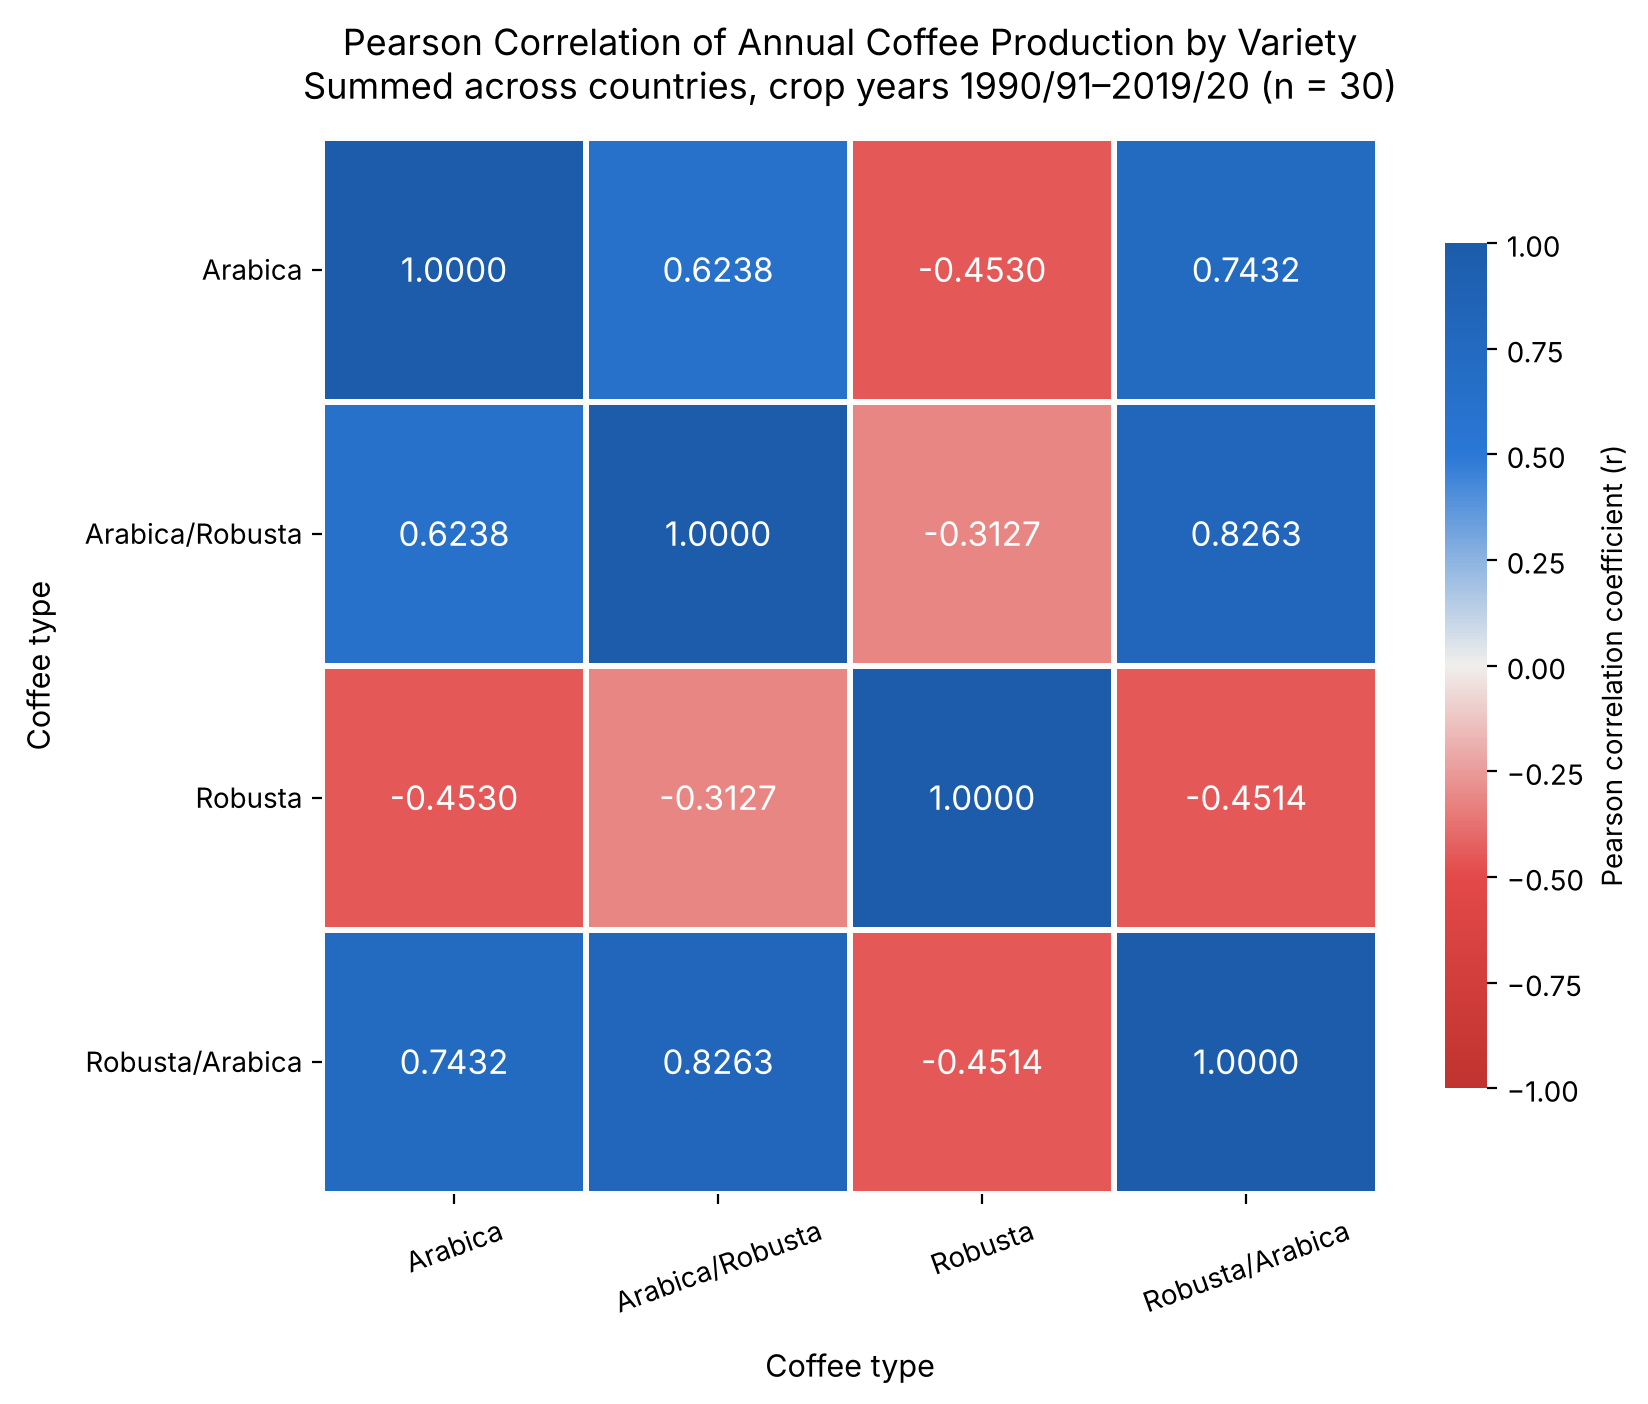

In [14]:
diverging = LinearSegmentedColormap.from_list(
    "neg_red_pos_blue", ["#c0332f", "#e34948", "#f0efec", "#2a78d6", "#1c5cab"]
)

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".4f",
    cmap=diverging,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=2,
    linecolor="#fcfcfb",
    annot_kws={"size": 12},
    cbar_kws={"label": "Pearson correlation coefficient (r)", "shrink": 0.8},
    ax=ax,
)
ax.set_title(
    "Pearson Correlation of Annual Coffee Production by Variety\n"
    "Summed across countries, crop years 1990/91–2019/20 (n = 30)",
    fontsize=13, pad=14,
)
ax.set_xlabel("Coffee type", fontsize=11, labelpad=10)
ax.set_ylabel("Coffee type", fontsize=11, labelpad=10)
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

### Annual Production Trends

The four groups differ in size by more than an order of magnitude, so a single
absolute-scale chart would flatten the smaller groups. The figure therefore has two
panels on separate, clearly labelled axes: **(a)** absolute production and **(b)** each
series indexed to its 1990/91 level (= 100), which shows relative growth. Correlation
compares the *shape* of each series, which panel (b) makes easier to see.

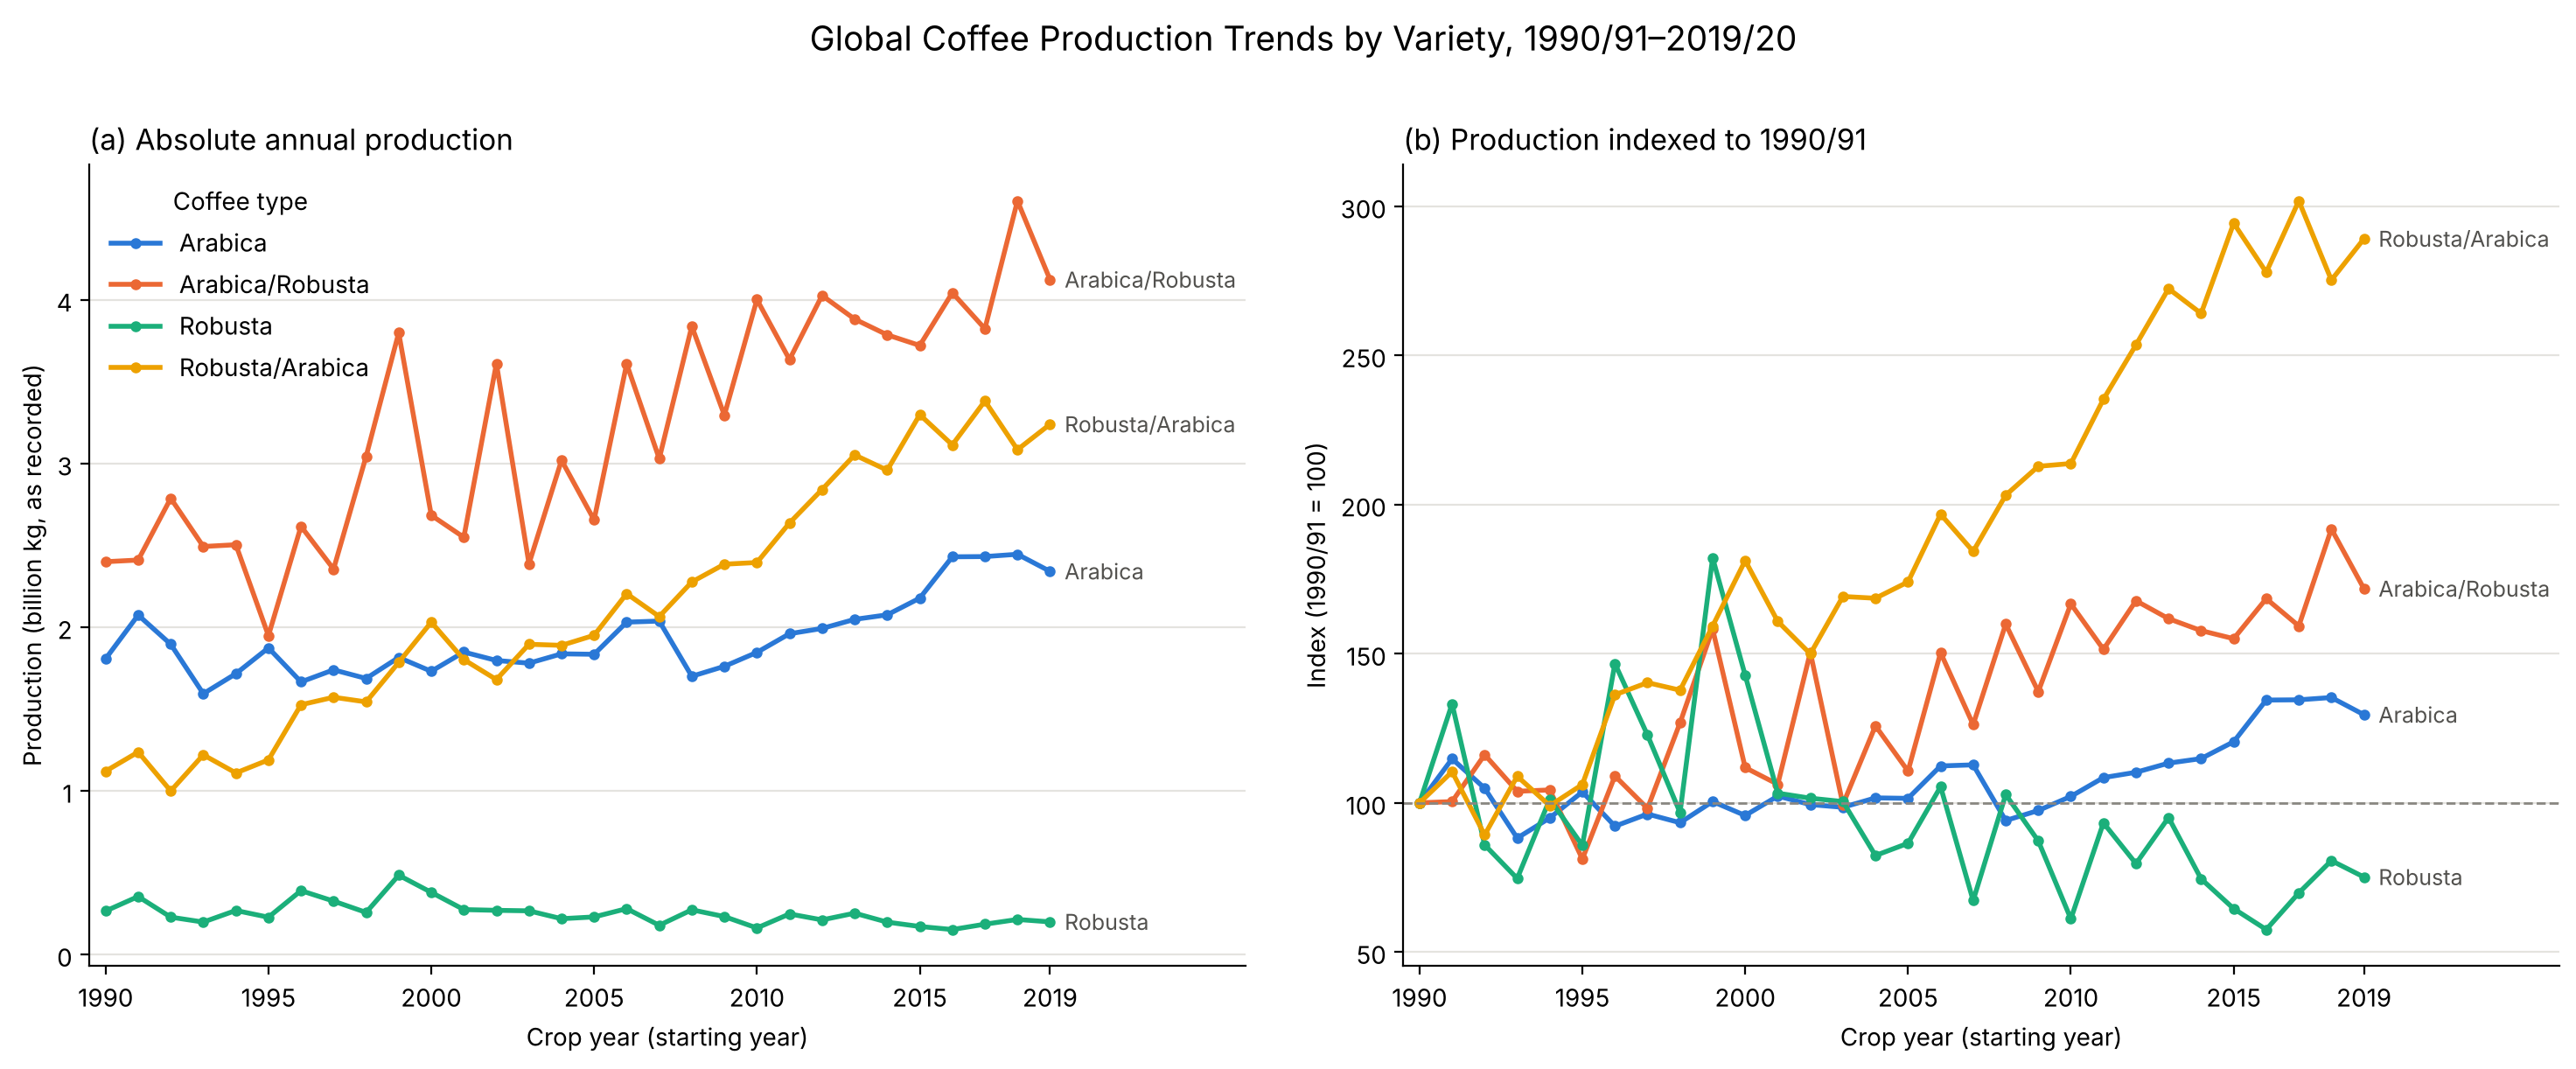

In [15]:
COLORS = {  # fixed order; colour follows the coffee type in every chart
    "Arabica": "#2a78d6",
    "Arabica/Robusta": "#eb6834",
    "Robusta": "#1baf7a",
    "Robusta/Arabica": "#eda100",
}
years_start = [int(y.split("_")[0]) for y in transposed.index]
indexed = transposed / transposed.iloc[0] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
panels = [
    (axes[0], transposed / 1e9, "Production (billion kg, as recorded)", "(a) Absolute annual production"),
    (axes[1], indexed, "Index (1990/91 = 100)", "(b) Production indexed to 1990/91"),
]
for ax, data, ylabel, title in panels:
    for coffee_type in transposed.columns:
        ax.plot(years_start, data[coffee_type], color=COLORS.get(coffee_type), linewidth=2,
                marker="o", markersize=3.5, label=coffee_type)
        # Direct label at the line end so identity is never colour-alone.
        ax.annotate(coffee_type, (years_start[-1], data[coffee_type].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=9, color="#52514e")
    ax.set_title(title, fontsize=12, loc="left")
    ax.set_xlabel("Crop year (starting year)")
    ax.set_ylabel(ylabel)
    ax.set_xlim(years_start[0] - 0.5, years_start[-1] + 6)
    ax.set_xticks([1990, 1995, 2000, 2005, 2010, 2015, 2019])
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].axhline(100, color="#898781", linewidth=1, linestyle="--")
axes[0].legend(title="Coffee type", frameon=False, loc="upper left")
fig.suptitle("Global Coffee Production Trends by Variety, 1990/91–2019/20", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "production_trends.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Identify the Strongest and Weakest Production Pairs

We list each **unique pair of different coffee types** once. Taking only combinations
(not permutations) drops the mirrored duplicates (A–B vs B–A), and the self-correlations
on the diagonal are excluded.

- **Strongest positive pair** = the largest $r$ (most positive).
- **Weakest pair** = the $r$ **closest to zero**, i.e. the smallest $|r|$.

For context we also report the t-statistic $t = r\sqrt{n-2}/\sqrt{1-r^2}$ with $n=30$
($df = 28$). The two-tailed 5% critical value is $t \approx 2.048$, which corresponds to
$|r| \approx 0.361$. This is a guide only: trending time series are autocorrelated, which
makes ordinary significance tests over-optimistic.

In [16]:
n_obs = len(transposed)
pairs = pd.DataFrame(
    [(a, b, corr_matrix.loc[a, b]) for a, b in combinations(corr_matrix.columns, 2)],
    columns=["Coffee type A", "Coffee type B", "Pearson r"],
).dropna(subset=["Pearson r"])
pairs["|r|"] = pairs["Pearson r"].abs()
pairs["t-statistic (df=28)"] = pairs["Pearson r"] * np.sqrt(n_obs - 2) / np.sqrt(1 - pairs["Pearson r"] ** 2)
pairs = pairs.sort_values("Pearson r", ascending=False).reset_index(drop=True)

assert len(pairs) == len(valid_types) * (len(valid_types) - 1) // 2  # 6 unique pairs for 4 types
display(pairs.round(4))

strongest = pairs.loc[pairs["Pearson r"].idxmax()]
weakest = pairs.loc[pairs["|r|"].idxmin()]

print(f"Strongest positive pair: {strongest['Coffee type A']} & {strongest['Coffee type B']}  r = {strongest['Pearson r']:.4f}")
print(f"Weakest (closest to 0) : {weakest['Coffee type A']} & {weakest['Coffee type B']}  r = {weakest['Pearson r']:.4f}")

,Coffee type A,Coffee type B,Pearson r,|r|,t-statistic (df=28)
0,Arabica/Robusta,Robusta/Arabica,0.8263,0.8263,7.7616
1,Arabica,Robusta/Arabica,0.7432,0.7432,5.8782
2,Arabica,Arabica/Robusta,0.6238,0.6238,4.2236
3,Arabica/Robusta,Robusta,-0.3127,0.3127,-1.7418
4,Robusta,Robusta/Arabica,-0.4514,0.4514,-2.6770
5,Arabica,Robusta,-0.4530,0.4530,-2.6891


Strongest positive pair: Arabica/Robusta & Robusta/Arabica  r = 0.8263
Weakest (closest to 0) : Arabica/Robusta & Robusta  r = -0.3127


In [17]:
# Supporting evidence for the reflection: long-run growth of each group.
growth = pd.DataFrame({
    "1990/91 (billions)": transposed.iloc[0] / 1e9,
    "2019/20 (billions)": transposed.iloc[-1] / 1e9,
    "Change (%)": (transposed.iloc[-1] / transposed.iloc[0] - 1) * 100,
    "Coefficient of variation (%)": transposed.std() / transposed.mean() * 100,
})
display(growth.round(2))

# Largest contributors to each group over 30 years.
top = (
    df.assign(**{"30-year total": df[YEAR_COLS].sum(axis=1)})
      .sort_values("30-year total", ascending=False)
      .groupby(TYPE_COL)
      .head(3)[[TYPE_COL, "Country", "30-year total"]]
)
top["Share of group (%)"] = top["30-year total"] / top[TYPE_COL].map(aggregated.sum(axis=1)) * 100
display(top.sort_values([TYPE_COL, "30-year total"], ascending=[True, False]).round(1).reset_index(drop=True))

,1990/91 (billions),2019/20 (billions),Change (%),Coefficient of variation (%)
Coffee type,,,,
Arabica,1.81,2.34,29.54,12.26
Arabica/Robusta,2.40,4.12,71.80,21.85
Robusta,0.27,0.20,-24.89,29.01
Robusta/Arabica,1.12,3.24,189.11,35.05


,Coffee type,Country,30-year total,Share of group (%)
0,Arabica,Colombia,2.159862e+10,37.3
1,Arabica,Ethiopia,8.669520e+09,15.0
2,Arabica,Honduras,6.672720e+09,11.5
3,Arabica/Robusta,Brazil,7.508298e+10,77.7
4,Arabica/Robusta,Mexico,7.853520e+09,8.1
5,Arabica/Robusta,Guatemala,7.020540e+09,7.3
6,Robusta,Côte d'Ivoire,4.761420e+09,62.5
7,Robusta,Madagascar,1.045560e+09,13.7
8,Robusta,Lao People's Democratic Republic,5.680800e+08,7.5
9,Robusta/Arabica,Viet Nam,2.880318e+10,45.4


## 10. Statistical Reflection

The coefficients quoted below come from the correlation matrix computed above. The next
code cell **asserts** that these quoted values still match the computation, so the
written answers cannot silently drift from the data if the notebook is re-run.

In [18]:
# Guard: the written reflection below quotes these exact values.
assert {strongest["Coffee type A"], strongest["Coffee type B"]} == {"Arabica/Robusta", "Robusta/Arabica"}
assert round(strongest["Pearson r"], 4) == 0.8263
assert {weakest["Coffee type A"], weakest["Coffee type B"]} == {"Arabica/Robusta", "Robusta"}
assert round(weakest["Pearson r"], 4) == -0.3127
assert round(strongest["t-statistic (df=28)"], 2) == 7.76
assert round(weakest["t-statistic (df=28)"], 2) == -1.74

# Supporting figures quoted in the text (rounded as written).
pct = growth["Change (%)"].round(0)
assert (pct["Arabica/Robusta"], pct["Robusta/Arabica"], pct["Robusta"]) == (72, 189, -25)
start, end = growth["1990/91 (billions)"].round(2), growth["2019/20 (billions)"].round(2)
assert (start["Arabica/Robusta"], end["Arabica/Robusta"]) == (2.40, 4.12)
assert (start["Robusta/Arabica"], end["Robusta/Arabica"]) == (1.12, 3.24)
assert (start["Robusta"], end["Robusta"]) == (0.27, 0.20)
share = top.set_index("Country")["Share of group (%)"].round(0)
assert (share["Brazil"], share["Viet Nam"], share["Indonesia"], share["Côte d'Ivoire"]) == (78, 45, 24, 63)
off_diag = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool)).stack()
assert off_diag[off_diag > 0].round(2).agg(["min", "max"]).tolist() == [0.62, 0.83]
assert off_diag[off_diag < 0].round(2).agg(["max", "min"]).tolist() == [-0.31, -0.45]
print("Reflection values verified against the computed correlation matrix.")

Reflection values verified against the computed correlation matrix.


### Question 1: Strongest Production Pair

**Answer: Arabica/Robusta and Robusta/Arabica, r = 0.8263.**

**What the dataset shows.** This is the strongest positive correlation among the six
unique pairs and a strong linear relationship (t ≈ 7.76 with df = 28, well above the
≈ 2.05 guide value). Across the 30 crop years, seasons in which the mainly-Arabica
mixed producers had higher combined output were usually also seasons in which the
mainly-Robusta mixed producers did. Both groups grew strongly over the period:
Arabica/Robusta rose from about 2.40 to 4.12 billion (+72%) and Robusta/Arabica from
about 1.12 to 3.24 billion (+189%). Most of the shared pattern is this **common upward
long-run trend**, rather than identical year-to-year swings.

**Which countries drive it.** Each group is dominated by one producer. Brazil supplies
about 78% of the Arabica/Robusta total, and Viet Nam about 45% of the Robusta/Arabica
total (with Indonesia about 24%). So the coefficient largely reflects the parallel
expansion of Brazil and Viet Nam, the world's two largest producers.

**Plausible explanations (not tested by this dataset):**
- *Rising international demand:* growing world coffee consumption, including emerging
  markets and the expansion of instant and espresso blends that use both varieties,
  would reward output growth in both groups at the same time.
- *Investment and productivity:* both Brazil and Viet Nam modernized production during
  this period (mechanization, irrigation, higher-yielding varieties, and in Viet Nam a
  large planting expansion in the Central Highlands).
- *Shared market signals:* producers in both groups respond to the same global price
  cycles, so strong-price periods can encourage expansion everywhere.

**Correlation is not causation.** r = 0.8263 means the two series moved together, not
that one group's output affected the other's. Two series that both trend upward will
correlate strongly even if they have no direct connection: the trend itself, or a third
factor such as global demand, can produce the relationship. Establishing *why* would
require other data (prices, planted area, yields, weather) and methods that separate
the shared trend from year-to-year co-movement.

### Question 2: Weakest Production Pair

**Answer: Arabica/Robusta and Robusta, r = −0.3127** (the coefficient closest to zero,
|r| = 0.3127).

**What the dataset shows.** This is a weak, slightly negative linear relationship. Its
t-statistic (≈ −1.74, df = 28) falls short of the ≈ 2.05 guide value, so the data offer
no reliable evidence of any linear association between these two series. Knowing one
group's output in a given season tells you little about the other's. The two groups also
followed different long-run paths: Arabica/Robusta grew about 72%, while the pure Robusta
group, dominated by Côte d'Ivoire (about 63% of its 30-year total), fell from about 0.27
to 0.20 billion (−25%) and swung widely from year to year. The small negative sign mostly
reflects one group trending up while the other drifted down, not a mechanism linking them.

**Possible explanations (hypotheses only; this dataset contains no climate, pest,
regional or infrastructure variables):**
- *Climate and growing conditions:* Arabica is usually grown at higher, cooler altitudes
  and Robusta in hot, humid lowlands. The Arabica/Robusta group is mostly Latin American
  (Brazil, Mexico, Guatemala), while the Robusta group is mostly West and Central African
  (Côte d'Ivoire, Togo, Guinea). Weather shocks such as Brazilian frosts or droughts and
  West African rainfall variation would hit the two groups independently.
- *Pests and disease:* the varieties and regions face different pressures (for example,
  coffee leaf rust in Central America, or coffee wilt disease and the berry borer in
  parts of Africa), so outbreaks need not happen at the same time.
- *Infrastructure and institutions:* differences in investment, extension services,
  market liberalization, and political stability (Côte d'Ivoire's civil conflicts in the
  2000s, for instance) could explain why African Robusta output declined while Brazilian
  output expanded.

**What is supported vs. speculative.** The dataset supports only this: the two groups'
annual totals have a weak (|r| ≈ 0.31) and statistically unreliable linear relationship,
with opposite long-run trends. The climate, pest and infrastructure explanations are
plausible hypotheses from agricultural context. Testing them would need weather, disease
and investment data, which this dataset does not contain.

## 11. Final Conclusion

- **Method.** The 55 country records were grouped into four coffee classifications and
  summed per crop year. The matrix was transposed so the 30 crop years became
  observations, and a Pearson correlation matrix was computed. Diagonal values equal
  1.0, the matrix is symmetric, and the coefficients match an independent NumPy
  calculation.
- **Strongest pair.** Arabica/Robusta & Robusta/Arabica (r = 0.8263): both mixed-variety
  groups, led by Brazil and Viet Nam, expanded together over 30 years.
- **Weakest pair.** Arabica/Robusta & Robusta (r = −0.3127): no reliable linear
  relationship. The small, mostly African Robusta group declined while the large Latin
  American mixed group grew.
- **Broader pattern.** The three groups that grew (Arabica, Arabica/Robusta,
  Robusta/Arabica) are all positively correlated with one another (0.62–0.83). The pure
  Robusta group, which shrank, is negatively correlated with all three (−0.31 to −0.45).
- **Limitations.** Classifications are per country, so the groups are not species totals.
  Each group is dominated by one or two countries. n = 30 annual observations of trending
  series inflate correlations driven by shared trends. Pearson's r captures only linear
  association and says nothing about causation. A natural extension is to correlate
  year-over-year *changes* (first differences) to separate short-term co-movement from
  long-run trend.

*Figures saved to `figures/correlation_heatmap.png` and `figures/production_trends.png`.*